In [1]:
packages <- c("ggplot2", "patchwork")
for (pkg in packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(pkg, character.only = TRUE)))
}
git_root <- system("git rev-parse --show-toplevel", intern = TRUE)

In [2]:
final_plot_file_path <- file.path(git_root, "figures", "assembled_figures","figures", "final_plot.png")
# make the parent directory if it does not exist
if (!dir.exists(dirname(final_plot_file_path))) {
  dir.create(dirname(final_plot_file_path), recursive = TRUE)
}

In [3]:
pdo_workflow <- file.path(git_root,"figures/workflow_figures/figures/pdo_pipeline_figure.png")
cell_painting_montage <- file.path(git_root,"figures/assembled_figures/imported_media/cell_painting_assay_montage_NF0014_T1_C4-2.png")
featurization_types <- file.path(git_root,"figures/assembled_figures/imported_media/Feature_types_tall.png")
ibp_workflow <- file.path(git_root,"figures/workflow_figures/figures/profiling_workflow.png")
zedprofiler_logo <- file.path(git_root,"figures/assembled_figures/assets/logos/zedprofiler_icon.png")


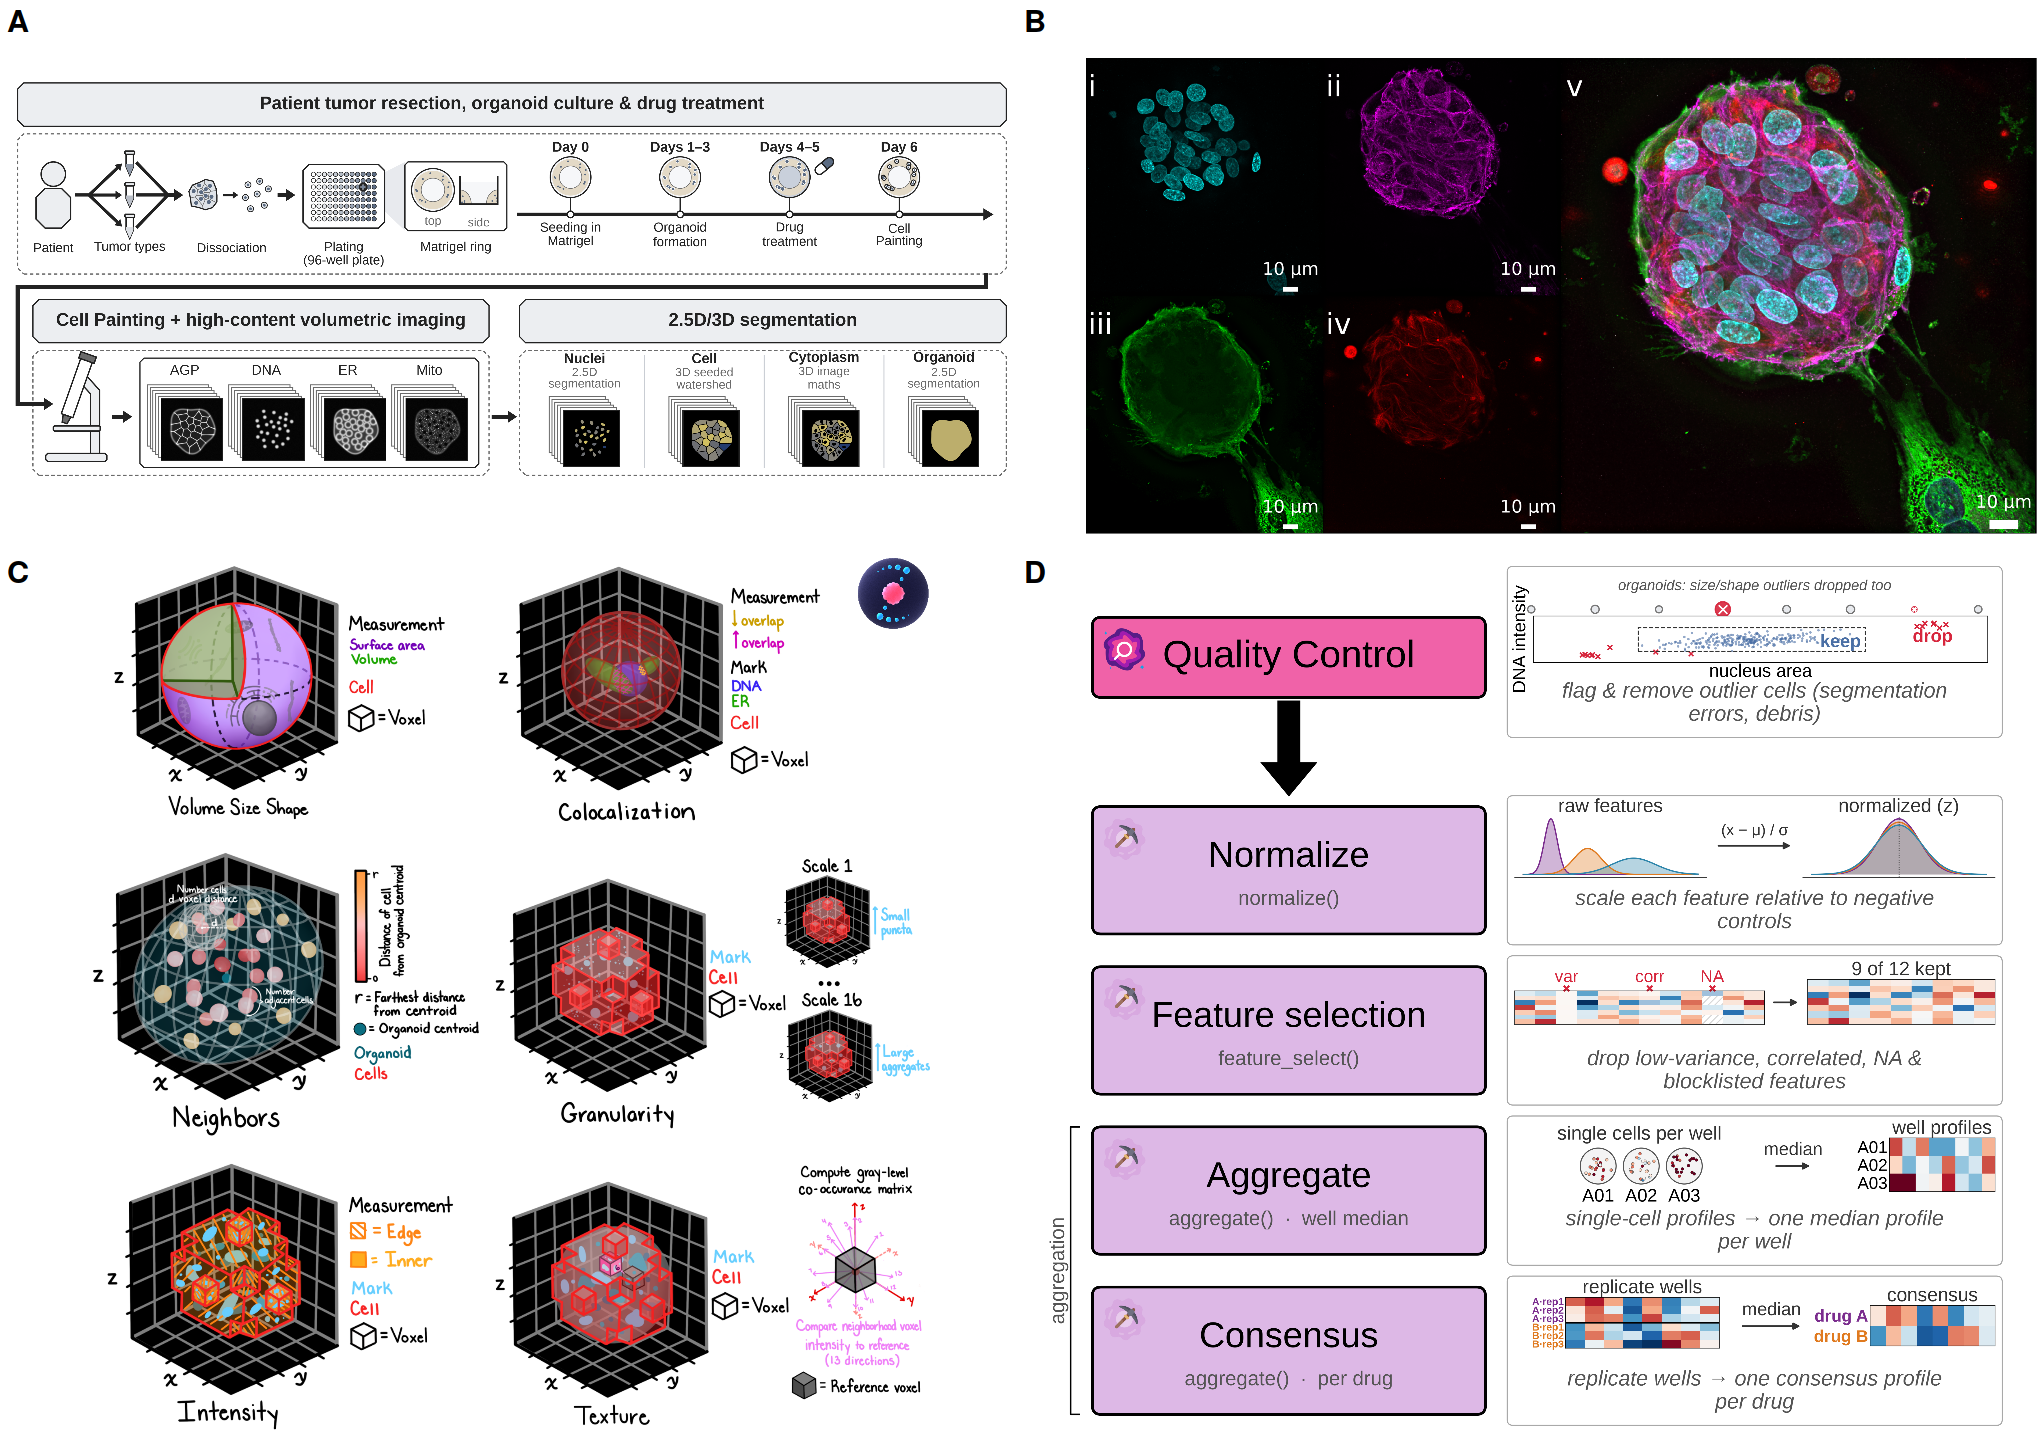

In [4]:
width <- 17
height <- 12
options(repr.plot.width = width, repr.plot.height = height)
# patchwork layout
layout <- "
AB
CD
CD
"

# B's source image has no blank margin at its top-left corner (unlike A, C, D),
# so the automatic patchwork tag has nowhere to sit without overlapping the
# image content. Pad just that image with white space before rasterizing it,
# rather than changing how any panel is laid out.
pad_top_left <- function(img, pad_frac = 0.07) {
    d <- dim(img)
    h <- d[1]; w <- d[2]; chans <- d[3]
    pad_h <- round(h * pad_frac)
    pad_w <- round(w * pad_frac)
    out <- array(1, dim = c(h + pad_h, w + pad_w, chans))
    out[(pad_h + 1):(h + pad_h), (pad_w + 1):(w + pad_w), ] <- img
    out
}

# Each source PNG carries its own blank white border (baked in when it was
# rendered/exported), and those borders get rescaled along with everything
# else when patchwork stretches the raster to fill its grid cell -- that is
# almost all of the dead space between panels in the assembled figure, not
# spacing patchwork itself adds. Trim each one down to a small fixed pad
# before placing it, rather than carrying its native border into the collage.
trim_white <- function(img, tol = 0.97, pad_frac = 0.012) {
    d <- dim(img)
    h <- d[1]; w <- d[2]
    bg <- (img[, , 1] > tol) & (img[, , 2] > tol) & (img[, , 3] > tol)
    rows <- which(rowMeans(bg) < 0.995)
    cols <- which(colMeans(bg) < 0.995)
    pad_h <- round(h * pad_frac)
    pad_w <- round(w * pad_frac)
    r0 <- max(1, min(rows) - pad_h); r1 <- min(h, max(rows) + pad_h)
    c0 <- max(1, min(cols) - pad_w); c1 <- min(w, max(cols) + pad_w)
    img[r0:r1, c0:c1, , drop = FALSE]
}

# Alpha-composite a logo directly into an RGB(A) image array, rather than
# adding it as a separate patchwork inset_element: an inset is its own
# taggable patch, and combining it with pC confused patchwork's auto-tag
# counter (panel C's letter went missing and D was mislabeled "C"). Baking
# the badge into the pixel array keeps panel C a single plain raster, so
# auto-tagging stays simple and correct.
resize_img <- function(img, out_h, out_w) {
    d <- dim(img); h <- d[1]; w <- d[2]
    ry <- pmin(h, pmax(1, round(seq(1, h, length.out = out_h))))
    rx <- pmin(w, pmax(1, round(seq(1, w, length.out = out_w))))
    img[ry, rx, , drop = FALSE]
}

composite_badge <- function(base, badge, left, top, badge_w_frac) {
    d <- dim(base); h <- d[1]; w <- d[2]
    bw <- round(badge_w_frac * w)
    bh <- round(bw * dim(badge)[1] / dim(badge)[2])
    x0 <- round(left * w) + 1; x1 <- min(w, x0 + bw - 1)
    y0 <- round(top * h) + 1;  y1 <- min(h, y0 + bh - 1)
    b <- resize_img(badge, y1 - y0 + 1, x1 - x0 + 1)
    alpha <- if (dim(b)[3] >= 4) b[, , 4] else array(1, dim = dim(b)[1:2])
    for (ch in 1:3) {
        base[y0:y1, x0:x1, ch] <- base[y0:y1, x0:x1, ch] * (1 - alpha) + b[, , ch] * alpha
    }
    base
}

featurization_arr <- trim_white(png::readPNG(featurization_types))
zedprofiler_arr <- png::readPNG(zedprofiler_logo)
featurization_arr <- composite_badge(
    featurization_arr, zedprofiler_arr,
    left = 0.90, top = 0.0, badge_w_frac = 0.09
)

pA <- wrap_elements(full = grid::rasterGrob(trim_white(png::readPNG(pdo_workflow)), interpolate = TRUE))
pB <- wrap_elements(full = grid::rasterGrob(pad_top_left(trim_white(png::readPNG(cell_painting_montage))), interpolate = TRUE))
pC <- wrap_elements(full = grid::rasterGrob(featurization_arr, interpolate = TRUE))
pD <- wrap_elements(full = grid::rasterGrob(trim_white(png::readPNG(ibp_workflow)), interpolate = TRUE))

final_plot <- (
    wrap_plots(A = pA, B = pB, C = pC, D = pD, design = layout)
    # Row 1 (A, B) was leaving more unused white space below it than rows
    # 2-3 (C, D) at equal heights; giving it a bit more relative height
    # lets A and B (especially B) grow into that space.
    + plot_layout(heights = c(1.22, 1, 1))
    + plot_annotation(tag_levels = 'A')
    & theme(
        plot.tag = element_text(face = "bold", size = 18),
        plot.margin = margin(2, 2, 2, 2)
    )
)
# save the final plot
ggsave(final_plot_file_path, plot = final_plot, width = width, height = height, dpi = 600)
final_plot